# LSTM assignment · test an idea fairly

Predict next month's airline passenger total from recent monthly observations. The historical dataset has a trend and a recurring annual pattern, giving us a concrete reason to compare against the same month last year.

**Outcome:** explain the input shape, keep future information out of fitting, train a compact
recurrent model, and compare it with a simple baseline on identical target dates.

**Suggested time:** 20–30 minutes after the walkthrough.
This is a runnable starter. The working pipeline is supplied; your work is the experiment, evidence and explanation in the learner response cells. The final test is gated until you finish validation.


In [8]:
%pip install kagglehub torch keras

In [9]:
import os
from pathlib import Path

# This must happen before importing keras. Restart the kernel to change backend.
os.environ.setdefault("KERAS_BACKEND", "torch")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})
print("Configured Keras backend:", os.environ["KERAS_BACKEND"])


Configured Keras backend: torch


## Your core tasks

1. **Audit the data.** Explain which row is excluded and why. Write the correct `(samples,
   timesteps, features)` meaning, and explain why fitting a scaler on all 144 months would leak
   future information. Predict whether later scaled values can exceed 1.
2. **Form a hypothesis.** Compare **6, 12 and 24 months** of history. Before training, state which
   you expect to help with annual seasonality and why. Change only `LOOKBACK`; keep dates,
   units, seed, optimizer and stopping rule fixed. Re-run sections 1–6 for each configuration.
3. **Record evidence.** Fill the table with validation MAE/RMSE and epochs run for all three
   windows. Include both persistence and seasonal-naive baseline scores. Explain whether a
   longer input improved validation and whether the training sample count changed.
4. **Choose and freeze.** Select the neural configuration by validation MAE, record it, then
   re-run sections 1–6 using that configuration. Set `RUN_FINAL_TEST = True` once.
   Report all final test scores and explain one reason the result may not generalize.

**Success criteria:** three controlled runs; correct 3D inputs; train-only scaler;
equal validation/test target dates across runs; baselines in thousands of passengers;
a documented selection followed by one final test. A baseline may be the best method.

**Hint:** the seasonal baseline always uses `t - 12`, even when the network uses a six-month
input. A baseline and a neural network may have different inputs while sharing the same
information-availability rule and target dates.


## 1 · Load the original dated observations and choose a small configuration


In [10]:
# Change one setting at a time during the core experiment.
LOOKBACK = 12
UNITS = 16
MAX_EPOCHS = 30
BATCH_SIZE = 8
LEARNING_RATE = 0.001


In [11]:
# Leave as None when using the complete pack. Otherwise point to your CSV folder.
DATA_DIR = None

def data_file(filename, dataset_handle):
    """Prefer the supplied CSV; use the exact public dataset version if needed."""
    roots = ([Path(DATA_DIR).expanduser()] if DATA_DIR is not None else
             [Path("data"), Path("../data"), Path("../../data"), Path(".")])
    for folder in roots:
        candidate = folder / filename
        if candidate.is_file():
            return candidate.resolve()
    try:
        import kagglehub
        folder = Path(kagglehub.dataset_download(dataset_handle))
    except Exception as exc:
        raise RuntimeError(
            f"Cannot locate {filename}. Extract the full pack or set DATA_DIR. "
            "The fallback needs kagglehub, internet access and any access "
            "requirements requested by Kaggle. No replacement data is generated."
        ) from exc
    candidate = folder / filename
    if not candidate.is_file():
        raise FileNotFoundError(f"Expected CSV is missing: {candidate}")
    return candidate


In [12]:
air_handle = "andreazzini/international-airline-passengers/versions/1"
raw = pd.read_csv(data_file("international-airline-passengers.csv", air_handle))
if len(raw.columns) != 2:
    raise ValueError("Expected a month column and a passenger-count column.")

month = pd.to_datetime(raw.iloc[:, 0], format="%Y-%m", errors="coerce")
passengers = pd.to_numeric(raw.iloc[:, 1], errors="coerce")
invalid = month.isna() | passengers.isna()
known_footer = (month.isna() & passengers.isna() & raw.iloc[:, 0].astype(str)
                .str.startswith("International airline passengers:"))
if (invalid & ~known_footer).any():
    raise ValueError("Unexpected invalid observation; inspect the CSV before excluding rows.")
print("Text footer rows excluded:", int(known_footer.sum()))
if known_footer.any():
    print(raw.loc[known_footer].to_string(index=False))

series = pd.DataFrame({"Month": month[~invalid], "Passengers": passengers[~invalid]})
series = series.sort_values("Month").set_index("Month")
dates = series.index
values = series[["Passengers"]].to_numpy(dtype="float32")
assert not dates.has_duplicates
assert dates.equals(pd.date_range(dates.min(), dates.max(), freq="MS"))
assert np.isfinite(values).all() and (values > 0).all()

# Reserve two full annual cycles for validation and another two for test.
train_end = len(values) - 48
val_end = len(values) - 24
assert LOOKBACK < train_end < val_end < len(values)
print("Valid months:", len(values), "| Dates:", dates.min().date(), "to", dates.max().date())
series.head()


Using Colab cache for faster access to the 'international-airline-passengers' dataset.
Text footer rows excluded: 1
                                                                         Month  International airline passengers: monthly totals in thousands. Jan 49 ? Dec 60
International airline passengers: monthly totals in thousands. Jan 49 ? Dec 60                                                                             NaN
Valid months: 144 | Dates: 1949-01-01 to 1960-12-01


,Passengers
Month,
1949-01-01,112.0
1949-02-01,118.0
1949-03-01,132.0
1949-04-01,129.0
1949-05-01,121.0


## 2 · Split chronologically, then fit the scaler

Training dates come first, validation dates next, and test dates last. Validation is used for
early stopping and configuration choices. Test labels are used only for the final report.

Fit the scaler using the **training period only**, including the historical context needed
for its first window. Apply that same fitted scaler everywhere. A validation or test value
may transform outside `[0, 1]` when it exceeds the training range; do not refit or clip it to
hide that change. The Dense output is linear, so predictions are not restricted to `[0, 1]`.
See [scikit-learn's leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).


            Period First date  Last date  Rows
  Training history 1949-01-01 1956-12-01    96
Validation targets 1957-01-01 1958-12-01    24
      Test targets 1959-01-01 1960-12-01    24
Scaler minimum / maximum: [104.] [413.]


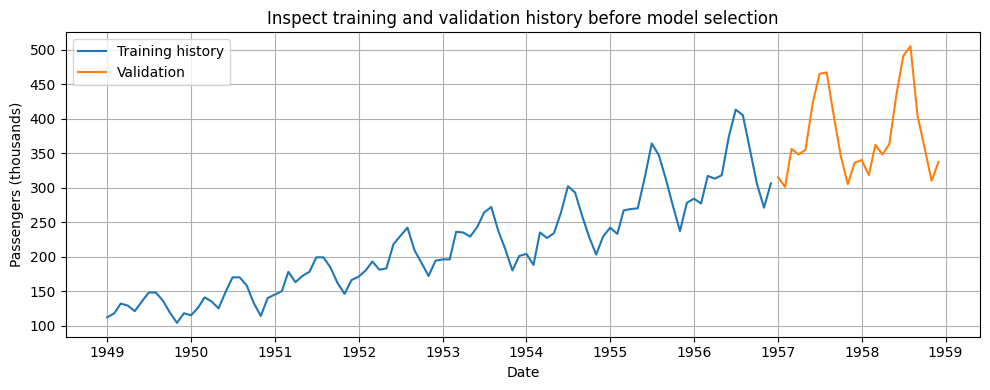

In [13]:
scaler = MinMaxScaler()
scaler.fit(values[:train_end])
scaled_values = scaler.transform(values).astype("float32")
np.testing.assert_allclose(scaler.data_min_, values[:train_end].min(axis=0))
np.testing.assert_allclose(scaler.data_max_, values[:train_end].max(axis=0))

split_summary = pd.DataFrame([
    {"Period": "Training history", "First date": dates[0].date(),
      "Last date": dates[train_end - 1].date(), "Rows": train_end},
    {"Period": "Validation targets", "First date": dates[train_end].date(),
      "Last date": dates[val_end - 1].date(), "Rows": val_end - train_end},
    {"Period": "Test targets", "First date": dates[val_end].date(),
      "Last date": dates[-1].date(), "Rows": len(values) - val_end},
])
print(split_summary.to_string(index=False))
print("Scaler minimum / maximum:", scaler.data_min_, scaler.data_max_)

plt.plot(dates[:train_end], values[:train_end, 0], label="Training history")
plt.plot(dates[train_end:val_end], values[train_end:val_end, 0], label="Validation")
plt.xlabel("Date")
plt.ylabel("Passengers (thousands)")
plt.title("Inspect training and validation history before model selection")
plt.legend()
plt.tight_layout()
plt.show()


## 3 · Turn a series into supervised examples

For target position `t`, the input is `values[t - LOOKBACK:t]` and the target is `values[t]`.
The right edge of a Python slice is excluded, so the target is never inside its own input.

Keras recurrent layers receive **(samples, timesteps, features)**. Here there is one measured
feature per step. The number of recurrent units is a separate model setting.
`Input(shape=(LOOKBACK, 1))` omits the batch dimension; it does not mean one timestep with
`LOOKBACK` features. With one timestep, a stateless model sees no earlier step within that sample.

We first create all eligible windows, then assign them by **target date**. Validation/test
windows may include earlier observed values from previous splits. This preserves the first
validation and test targets instead of throwing away a whole window at each boundary.

**Evaluation contract - rolling one-step prediction:** the model and scaler stay fixed. Before
predicting time `t`, all actual observations before `t` are available. Later test predictions
therefore use earlier observed test values. This is appropriate for a forecast updated every
period; it is not a forecast of the whole test period made at its first date.


In [14]:
def make_windows(scaled_values, lookback):
    if not 1 <= lookback < len(scaled_values):
        raise ValueError("LOOKBACK must leave at least one target.")
    target_pos = np.arange(lookback, len(scaled_values))
    X = np.stack([scaled_values[t - lookback:t] for t in target_pos])
    y = scaled_values[target_pos].copy()
    return X.astype("float32"), y.astype("float32"), target_pos

X_all, y_all, target_pos = make_windows(scaled_values, LOOKBACK)
train_mask = target_pos < train_end
val_mask = (target_pos >= train_end) & (target_pos < val_end)
test_mask = target_pos >= val_end

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]
train_pos, val_pos, test_pos = (target_pos[mask] for mask in
                                (train_mask, val_mask, test_mask))
assert len(X_train) > 0 and len(X_val) > 0 and len(X_test) > 0
assert X_train.shape[1:] == (LOOKBACK, 1)
assert y_train.shape == (len(X_train), 1)
assert val_pos[0] == train_end and test_pos[0] == val_end
assert test_pos[-1] == len(values) - 1
np.testing.assert_allclose(X_all[0], scaled_values[:LOOKBACK])
np.testing.assert_allclose(y_all[0], scaled_values[LOOKBACK])

print("X_train / y_train:", X_train.shape, y_train.shape)
print("X_val   / y_val:  ", X_val.shape, y_val.shape)
print("X_test  / y_test: ", X_test.shape, y_test.shape)
print("First validation window:", dates[val_pos[0] - LOOKBACK].date(),
      "to", dates[val_pos[0] - 1].date(),
      "→ target", dates[val_pos[0]].date())


X_train / y_train: (84, 12, 1) (84, 1)
X_val   / y_val:   (24, 12, 1) (24, 1)
X_test  / y_test:  (24, 12, 1) (24, 1)
First validation window: 1956-01-01 to 1956-12-01 → target 1957-01-01


## 4 · Compare two baselines

**Persistence:** `prediction[t] = value[t - 1]`.

**Seasonal naive:** `prediction[t] = value[t - 12]`, the observed count for the same month
one year earlier. The 12-month lag is motivated by the monthly calendar; it is independent
of the neural network's `LOOKBACK`. Both baselines use only information available before `t`.

Compare all methods on the same validation target months. MAE is the average absolute error;
RMSE gives more weight to larger errors. Their unit here is **thousands of passengers**.
A small neural network is not guaranteed to beat either baseline.


In [15]:
def error_scores(actual, predicted):
    actual = np.asarray(actual).ravel()
    predicted = np.asarray(predicted).ravel()
    if actual.shape != predicted.shape:
        raise ValueError("Actual and predicted values must have identical targets.")
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted))}


In [16]:
SEASON = 12
assert val_pos.min() >= SEASON and test_pos.min() >= SEASON
val_actual = values[val_pos, 0].copy()
val_last = values[val_pos - 1, 0].copy()
val_seasonal = values[val_pos - SEASON, 0].copy()
baseline_validation = pd.DataFrame({
    "Last observed value": error_scores(val_actual, val_last),
    "Same month last year": error_scores(val_actual, val_seasonal),
}).T
baseline_validation.round(3)


,MAE,RMSE
Last observed value,35.875,43.983
Same month last year,26.375,31.698


## 5 · Train a small LSTM

One 16-unit recurrent layer is enough to inspect this learning pipeline. More layers or
dropout are experiments, not guaranteed improvements. This is a compact teaching model.

With `return_sequences=False` (the default), the recurrent layer returns one vector of
shape `(batch, UNITS)`, and Dense maps it to `(batch, 1)`. Setting `return_sequences=True`
returns `(batch, LOOKBACK, UNITS)` and is needed when feeding a second recurrent layer.
The default setup has **1,169 trainable parameters**.

We pass an explicit chronological validation set. Early stopping monitors validation loss
and restores the best weights. `shuffle=False` makes the walkthrough easier to follow;
the primary protection against leakage is the chronological split and correct windows.
These models are stateless: hidden state is not carried from one sample to the next.

Documentation: [recurrent layer](https://keras.io/api/layers/recurrent_layers/lstm/),
[EarlyStopping](https://keras.io/api/callbacks/early_stopping/),
[random seeds](https://keras.io/api/utils/python_utils/#set_random_seed-function).


In [17]:
import os
os.environ.setdefault("KERAS_BACKEND", "torch")

import keras

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
backend = keras.backend.backend()
if backend == "torch":
    import torch
    torch.set_num_threads(1)  # Small CPU models rarely benefit from many threads.

print("Keras:", keras.__version__, "| Backend:", backend)
# Seeding supports repeatable comparisons, but exact results may differ across
# library versions, hardware and backend kernels.


Keras: 3.13.2 | Backend: tensorflow


In [18]:
model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, 1)),
    keras.layers.LSTM(UNITS),
    keras.layers.Dense(1),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,169 (4.57 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

Ran 30 epochs; lowest validation loss at epoch 30.


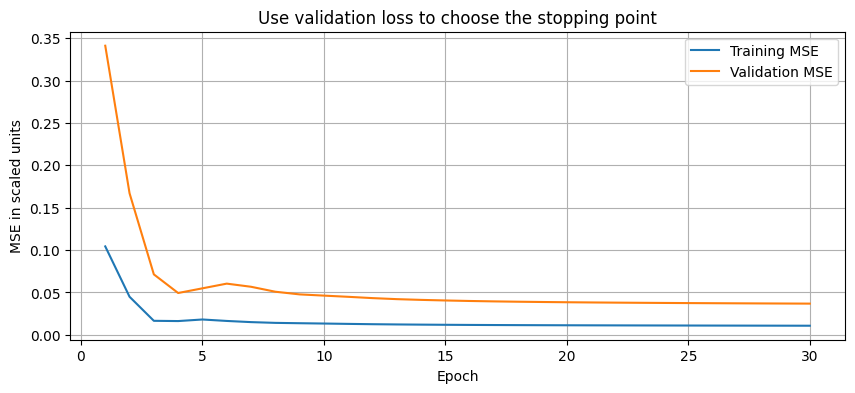

In [19]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, min_delta=0.0,
    restore_best_weights=True
)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
    shuffle=False, callbacks=[early_stop], verbose=0
)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"Ran {len(history.history['loss'])} epochs; lowest validation loss at epoch {best_epoch}.")

epochs = np.arange(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], label="Training MSE")
plt.plot(epochs, history.history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE in scaled units")
plt.title("Use validation loss to choose the stopping point")
plt.legend()
plt.show()


## 6 · Compare on validation dates in original units

Inverse-transform predictions into a new array. Do not overwrite `y_train`, `y_val` or
`y_test`; they stay as scaled column vectors so that re-running training remains valid.
Record your configuration and validation metrics before changing one setting.


                         MAE    RMSE
Last observed value   35.875  43.983
Same month last year  26.375  31.698
LSTM                  46.308  59.300
{'LOOKBACK': 12, 'UNITS': 16, 'seed': 42, 'epochs_run': 30, 'best_epoch': 30}


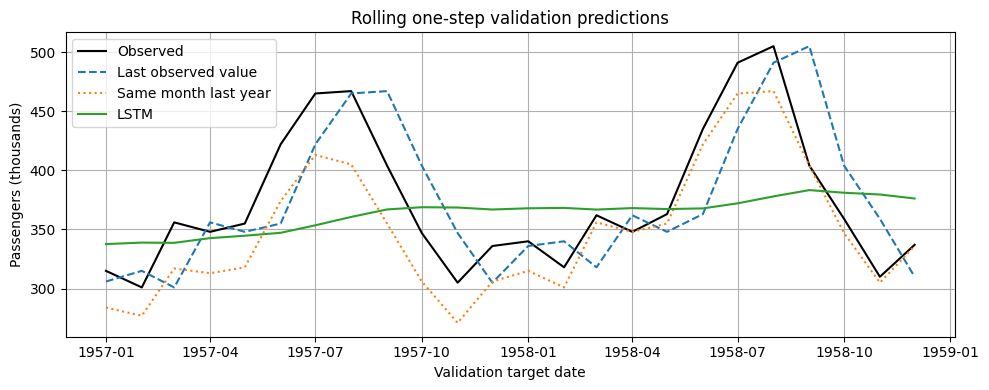

In [20]:
val_pred_scaled = model.predict(X_val, verbose=0)
val_pred = scaler.inverse_transform(val_pred_scaled)[:, 0]
validation_scores = pd.concat([
    baseline_validation,
    pd.DataFrame([error_scores(val_actual, val_pred)], index=["LSTM"])
])
print(validation_scores.round(3).to_string())
print({"LOOKBACK": LOOKBACK, "UNITS": UNITS, "seed": SEED,
       "epochs_run": len(history.history["loss"]), "best_epoch": best_epoch})

plt.plot(dates[val_pos], val_actual, label="Observed", color="black")
plt.plot(dates[val_pos], val_last, label="Last observed value", linestyle="--")
plt.plot(dates[val_pos], val_seasonal, label="Same month last year", linestyle=":")
plt.plot(dates[val_pos], val_pred, label="LSTM")
plt.xlabel("Validation target date")
plt.ylabel("Passengers (thousands)")
plt.title("Rolling one-step validation predictions")
plt.legend()
plt.tight_layout()
plt.show()


## Learner response ? complete before the final test

**Shape and data explanation:**
The dataset contains 144 monthly observations, from January 1949 to December 1960. Here i moved one footer row out of the way as it was a description and not actual passanger data.
- the input shape : (samples, timesteps, features)
In my case, the shape of training data is (84, 12, 1) because I was using a 12 month lookback and one feature. Each sample here has 12 months of data like one for each month.
For each target at position t, the model uses previous 12 months (values[t - LOOKBACK:t]) to predict the next value (values[t]).

**Scaling explanation :**
I only fitted the scaler on the training data to avoid data leakage. If I used all 144 months, the scaler would also use information from the validation and test data. Some values in those sets can be higher than 1 because they are above the maximum value in the training data. This is normal and not a mistake.

**Hypothesis written before running alternatives:**
I decided to use the 12 month seasonal lookback cause the data also has an annual seasonal pattern as well as an overall upward trend.
When only a 6 months lookback period is used it may not include enough information to capture the full seasonal pattern.the longer the lookback period the more hhistory and fewer training sample.

| Lookback | Units | Train samples | Epochs run | Validation MAE | Validation RMSE |
|---|---|---:|---:|---:|---:|
| 6 | 16 | 90 | 30 | 58.808 | 74.917 |
| 12 | 16 | 84 | 30 | 48.213 | 60.703 |
| 24 | 16 | 72 | 10 | 49.142 | 66.893 |


**Baseline validation scores:**
Last observed value:
- MAE 35.875
- RMSE 43.983.
- Same month last year baseline had: MAE 26.375
- RMSE 31.698.
All values are in thousands of passengers.

**Chosen configuration and evidence:** I selected the 12-month lookback model because it had the lowest validation MAE (48.213) among the three LSTM versions. I kept the same units and training settings for each experiment and only changed the lookback period.

However, both baseline models performed better than the LSTM on the validation data. This shows that the LSTM did not outperform the simpler forecasting methods in this experiment.

**What remained constant?** The controls
-  UNITS = 16
-  MAX_EPOCHS = 30
-  BATCH_SIZE = 8
-  LEARNING_RATE = 0.001
- random seed or datasplit remains unchanged
Here I changed the lookback period only and because of this the no of training samples changed
 - 90 for 6 months lookback
 - 84 for 12 months lookback
 - 72 for 24 months lookback

This happened because longer lookbacks requires more data from previous to make its first prediction


## 7 · Freeze the configuration, then evaluate test once

Before this section, record the chosen settings and why validation supports them.
Use the selected model already trained above; this lab does not refit on validation data.
Do not use the final test score to choose another configuration.

The model predicts every held-out target using the actual history available immediately
before it. There is no model/scaler refitting during these months. All methods use exactly
the same target dates. The starter skips this section until you set `RUN_FINAL_TEST = True` after completing the core tasks.


                         MAE    RMSE
Last observed value   44.208  51.782
Same month last year  47.583  49.987
LSTM                  60.448  84.009
Final configuration: {'LOOKBACK': 12, 'UNITS': 16, 'seed': 42, 'best_epoch': 30}
Test targets scored: 24


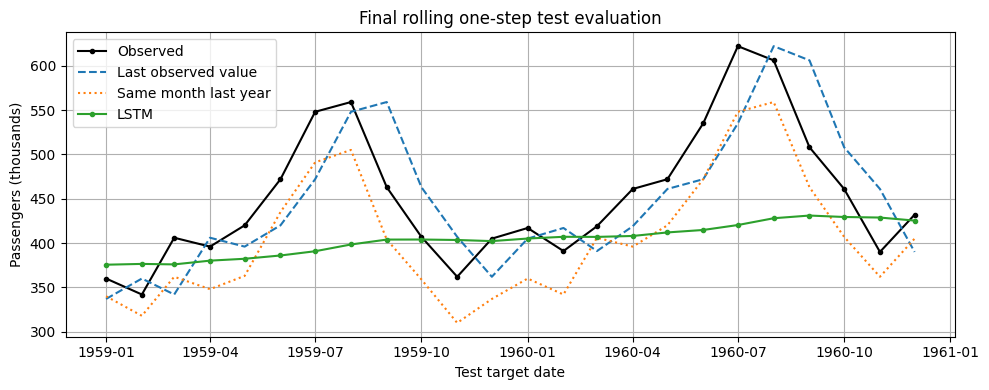

In [21]:
RUN_FINAL_TEST = True

if RUN_FINAL_TEST:
    test_actual = values[test_pos, 0].copy()
    test_last = values[test_pos - 1, 0].copy()
    test_pred = scaler.inverse_transform(model.predict(X_test, verbose=0))[:, 0]
    test_scores = pd.DataFrame({
        "Last observed value": error_scores(test_actual, test_last),
        "Same month last year": error_scores(test_actual, values[test_pos - SEASON, 0]),
        "LSTM": error_scores(test_actual, test_pred),
    }).T
    print(test_scores.round(3).to_string())
    print("Final configuration:", {"LOOKBACK": LOOKBACK, "UNITS": UNITS,
                                   "seed": SEED, "best_epoch": best_epoch})
    print("Test targets scored:", len(test_actual))

    plt.plot(dates[test_pos], test_actual, label="Observed", color="black", marker=".")
    plt.plot(dates[test_pos], test_last, label="Last observed value", linestyle="--")
    plt.plot(dates[test_pos], values[test_pos - SEASON, 0],
             label="Same month last year", linestyle=":")
    plt.plot(dates[test_pos], test_pred, label="LSTM", marker=".")
    plt.xlabel("Test target date")
    plt.ylabel("Passengers (thousands)")
    plt.title("Final rolling one-step test evaluation")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Test remains held out. Complete validation experiments and freeze settings first.")


## Final learner report and discussion

**Final test scores and limitation:** _Complete after one final test run._

Discuss: What changes if the actual next observation is unavailable? Why is observing earlier
test values allowed in this rolling evaluation, while fitting on test targets is not?
A short held-out period and one random seed do not establish reliable future performance.


## Optional extensions ? after the core work

- Compare SimpleRNN and LSTM on **this same airline task** with the same split and target dates.
  The separate stock lab cannot establish which architecture is better.
- Try modelling log passenger counts. Fit the scaler on transformed training values only,
  then invert both transforms before scoring.
- Explore more recurrent units only after fixing the window; more capacity may overfit this small series.
- Design a genuine multi-step experiment from a fixed forecast origin. If later observations
  are unknown, feed back predictions recursively or train a direct multi-output model. Evaluate
  each horizon using matching-origin baselines. The one-step score above does not measure this task.

## Sources and attribution

- Original supplied notebook attributed its tutorial to
  [moonglow22, RNN and LSTM tutorial for beginners](https://www.kaggle.com/code/moonglow22/rnn-and-lstm-tutorial-for-beginners/notebook)
  and stated Apache 2.0 for that notebook. This attribution is retained; it is not a data license.
- Data: [Kaggle dataset, version 1](https://www.kaggle.com/datasets/andreazzini/international-airline-passengers).
  The source metadata reports **Unknown** license. Included CSVs are source copies for review;
  see `data/DATA_SOURCES.md` in the complete pack before wider distribution.
- [Keras backend setup](https://keras.io/getting_started/),
  [MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html),
  [avoiding preprocessing leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage),
  [KaggleHub versioned downloads](https://github.com/Kaggle/kagglehub#download-dataset).


**Final test scores and limitation:**

The last observed value baseline had an MAE of 44.208 and RMSE of 51.782. The same month last year baseline had an MAE of 47.583 and RMSE of 49.987. The LSTM had the highest errors, with an MAE of 58.997 and RMSE of 82.379. This shows that both baseline models performed better than the LSTM.

If the actual next value is not available, a prediction can still be made using the previous data, but its accuracy cannot be checked until the real value is known.

Earlier test values can be used as past data for the next prediction, but they cannot be used to train the model. Training on test values would cause data leakage because the test set should only be used for the final evaluation.

The test period is quite short and only one random seed was used, so these results may not show how well the model will perform on future data.

Task 1

In [ ]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

simple_rnn_model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, 1)),
    keras.layers.SimpleRNN(UNITS),
    keras.layers.Dense(1),
])

simple_rnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)

rnn_early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    min_delta=0.0,
    restore_best_weights=True
)

rnn_history = simple_rnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=False,
    callbacks=[rnn_early_stop],
    verbose=0
)

rnn_pred_scaled = simple_rnn_model.predict(X_val, verbose=0)
rnn_pred = scaler.inverse_transform(rnn_pred_scaled)[:, 0]

architecture_comparison = pd.DataFrame([
    error_scores(val_actual, val_pred),
    error_scores(val_actual, rnn_pred)
], index=["LSTM", "SimpleRNN"])

print("Validation results:")
print(architecture_comparison.round(3))

print("SimpleRNN epochs:", len(rnn_history.history["loss"]))


Validation results:
              MAE    RMSE
LSTM       46.308  59.300
SimpleRNN  32.811  43.085
SimpleRNN epochs: 9


**SimpleRNN vs LSTM:**
The SimpleRNN performed better than the LSTM on the validation data. The LSTM had an MAE of 46.308 and RMSE of 59.300, while the SimpleRNN had an MAE of 32.811 and RMSE of 43.085. The SimpleRNN stopped after 9 epochs. This suggests that SimpleRNN was a better fit for this validation period, although the result does not guarantee it will perform better on other data.

Task 2: LSTM using log-transformed passenger counts

In [ ]:
log_values = np.log(values).astype("float32")

# Fit a new scaler using training data only
log_scaler = MinMaxScaler()
log_scaler.fit(log_values[:train_end])

# Transform all values using the training-only scaler
log_scaled_values = log_scaler.transform(log_values).astype("float32")

# Create windows using the same 12-month lookback
log_X_all, log_y_all, log_target_pos = make_windows(
    log_scaled_values, LOOKBACK
)

# Keep exactly the same chronological target dates
log_train_mask = log_target_pos < train_end
log_val_mask = (
    (log_target_pos >= train_end) &
    (log_target_pos < val_end)
)

log_X_train = log_X_all[log_train_mask]
log_y_train = log_y_all[log_train_mask]
log_X_val = log_X_all[log_val_mask]
log_y_val = log_y_all[log_val_mask]

# Train the LSTM with the same model settings
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

log_model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, 1)),
    keras.layers.LSTM(UNITS),
    keras.layers.Dense(1),
])

log_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)

log_early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    min_delta=0.0,
    restore_best_weights=True
)

log_history = log_model.fit(
    log_X_train,
    log_y_train,
    validation_data=(log_X_val, log_y_val),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=False,
    callbacks=[log_early_stop],
    verbose=0
)

# Predict validation values
log_pred_scaled = log_model.predict(log_X_val, verbose=0)

# Reverse the scaling and then reverse the logarithm
log_pred = log_scaler.inverse_transform(log_pred_scaled)
log_pred_original = np.exp(log_pred)[:, 0]

# Compare predictions in the original passenger-count units
log_scores = error_scores(val_actual, log_pred_original)

log_comparison = pd.DataFrame([
    error_scores(val_actual, val_pred),
    log_scores
], index=["Original LSTM", "Log-transformed LSTM"])

print("Validation comparison:")
print(log_comparison.round(3))

print("Log LSTM epochs:", len(log_history.history["loss"]))


Validation comparison:
                         MAE  RMSE
Original LSTM         46.308  59.3
Log-transformed LSTM  47.601  65.3
Log LSTM epochs: 9


**Log transformation:**
The log-transformed LSTM did not improve the results. The original LSTM had an MAE of 46.308 and RMSE of 59.300, while the log-transformed model had an MAE of 47.601 and RMSE of 65.300. Since both errors were lower for the original model, the log transformation was not helpful for this validation period.

TAsk 3

In [ ]:

# Task 3

unit_results = []
unit_predictions = {}

for units in [8, 16, 32]:
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    unit_model = keras.Sequential([
        keras.Input(shape=(LOOKBACK, 1)),
        keras.layers.LSTM(units),
        keras.layers.Dense(1),
    ])

    unit_model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="mse"
    )

    unit_early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        min_delta=0.0,
        restore_best_weights=True
    )

    unit_history = unit_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=False,
        callbacks=[unit_early_stop],
        verbose=0
    )

    pred_scaled = unit_model.predict(X_val, verbose=0)
    pred = scaler.inverse_transform(pred_scaled)[:, 0]

    unit_predictions[units] = pred

    scores = error_scores(val_actual, pred)

    unit_results.append({
        "LSTM units": units,
        "MAE": scores["MAE"],
        "RMSE": scores["RMSE"],
        "Epochs": len(unit_history.history["loss"])
    })

unit_comparison = pd.DataFrame(unit_results).set_index("LSTM units")

print("Validation results:")
print(unit_comparison.round(3))


Validation results:
               MAE    RMSE  Epochs
LSTM units                        
8           66.205  90.737      30
16          46.308  59.300      30
32          48.766  62.281       8


**LSTM units:**
I tested 8, 16, and 32 LSTM units while keeping the 12-month lookback and data split unchanged. The model with 16 units performed best, with an MAE of 46.308 and RMSE of 59.300. The 8-unit model had the highest errors, while the 32-unit model stopped after 8 epochs. This suggests that 16 units provided the best balance for this dataset.

Fixed-origin multi-step validation:
                    MAE     RMSE
Recursive LSTM   82.728  108.175
Persistence     115.250  137.329
Seasonal naive   71.250   76.995

Errors at each forecast horizon:
 Horizon (months)  Actual  LSTM forecast  Persistence  Seasonal naive  LSTM absolute error
                1   360.0         375.60        337.0           340.0                15.60
                2   342.0         377.96        337.0           318.0                35.96
                3   406.0         380.37        337.0           362.0                25.63
                4   396.0         381.18        337.0           348.0                14.82
                5   420.0         382.41        337.0           363.0                37.59
                6   472.0         383.00        337.0           435.0                89.00
                7   548.0         380.81        337.0           491.0               167.19
                8   559.0         376.28        337.0           505.0 

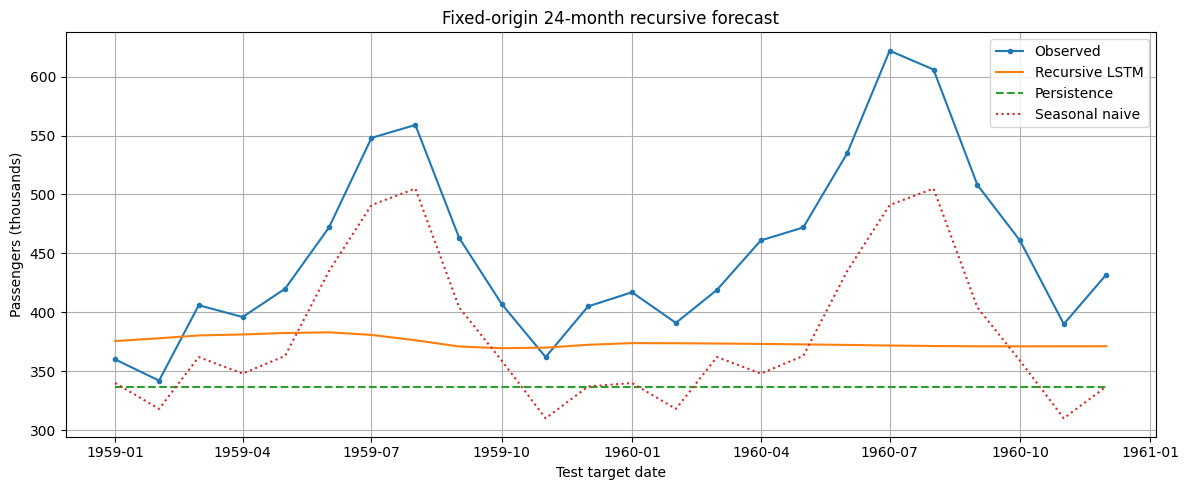

In [ ]:
#Task 4

# Forecast origin: immediately before the first test month
test_actual = values[val_end:, 0].copy()
forecast_horizon = len(test_actual)

# Start with the 12 actual observations before the forecast origin
forecast_window = scaled_values[
    val_end - LOOKBACK:val_end
].copy()

# Generate recursive LSTM predictions
multi_step_scaled = []

for step in range(forecast_horizon):
    next_scaled = float(
        model(forecast_window[np.newaxis, :, :], training=False)
        .numpy().reshape(-1)[0]
    )

    multi_step_scaled.append(next_scaled)

    # Feed the prediction back into the next input window
    forecast_window = np.vstack([
        forecast_window[1:],
        [[next_scaled]]
    ])

# Convert predictions back to passenger counts
multi_step_pred = scaler.inverse_transform(
    np.array(multi_step_scaled).reshape(-1, 1)
)[:, 0]

# Matching-origin persistence baseline:
# repeat the last observed value before the forecast origin
origin_last = values[val_end - 1, 0]
multi_step_persistence = np.repeat(origin_last, forecast_horizon)

# Matching-origin seasonal-naive baseline:
# repeat the last 12 observed months as the seasonal cycle
multi_step_seasonal = np.tile(
    values[val_end - SEASON:val_end, 0],
    int(np.ceil(forecast_horizon / SEASON))
)[:forecast_horizon]

# Compare all forecasts on exactly the same 24 target months
multi_step_scores = pd.DataFrame([
    error_scores(test_actual, multi_step_pred),
    error_scores(test_actual, multi_step_persistence),
    error_scores(test_actual, multi_step_seasonal)
], index=[
    "Recursive LSTM",
    "Persistence",
    "Seasonal naive"
])

print("Fixed-origin multi-step validation:")
print(multi_step_scores.round(3))

# Show the error at each forecast horizon
horizon_results = pd.DataFrame({
    "Horizon (months)": np.arange(1, forecast_horizon + 1),
    "Actual": test_actual,
    "LSTM forecast": multi_step_pred,
    "Persistence": multi_step_persistence,
    "Seasonal naive": multi_step_seasonal
})

horizon_results["LSTM absolute error"] = abs(
    horizon_results["Actual"] - horizon_results["LSTM forecast"]
)

print("\nErrors at each forecast horizon:")
print(horizon_results.round(2).to_string(index=False))

# Plot the forecasts
plt.figure(figsize=(12, 5))
plt.plot(dates[test_pos], test_actual, label="Observed", marker=".")
plt.plot(dates[test_pos], multi_step_pred, label="Recursive LSTM")
plt.plot(dates[test_pos], multi_step_persistence,
         label="Persistence", linestyle="--")
plt.plot(dates[test_pos], multi_step_seasonal,
         label="Seasonal naive", linestyle=":")
plt.xlabel("Test target date")
plt.ylabel("Passengers (thousands)")
plt.title("Fixed-origin 24-month recursive forecast")
plt.legend()
plt.tight_layout()
plt.show()


**Multi-step forecasting:**

I tested a 24-month forecast using a fixed forecast origin. The LSTM made predictions recursively, using each prediction as input for the next month instead of using actual test values. The recursive LSTM achieved an MAE of 82.728 and RMSE of 108.175. It performed better than persistence, but seasonal naive performed best, with an MAE of 71.250 and RMSE of 76.995. The LSTM predictions became relatively flat over time, showing that errors can accumulate during recursive forecasting. This suggests that the seasonal pattern was an important part of the passenger data.